# Notebook to design a method to find the Circoscription with an Address

## Step 1 : Normalize and Geolocate the address

API of the data base Adresse Nationale (BAN)

API Géoplateforme - Géocodage :
- user guide https://www.data.gouv.fr/dataservices/api-geoplateforme-geocodage
- swagger : https://data.geopf.fr/geocodage/openapi

In [2]:
#name of the server containing the geocoding service
server_name = "https://data.geopf.fr/geocodage"

## Search service of the Géoplateforme - Géocodage API
with GET Method

A noter : limite de 50 requêtes par seconde depuis une même adresse IP

In [19]:
#get method with requests library
import requests
import json

#address to geocode
address = "15 Rue Louis Colette, Nouméa 98800, Nouvelle-Calédonie"

response = requests.get(
    server_name + "/search", #endpoint of the geocoding service
    params={
        "q": address,
        "format": "json",
        "index": "address,poi", #index to search in, can be address or poi (point of interest or admin unit)
        "limit": "10" #max number of results to return
    }
)

response.raise_for_status() #raise an error if the request failed

test_address_geocode = response.json()

print(json.dumps(test_address_geocode, indent=4, ensure_ascii=False))

{
    "type": "FeatureCollection",
    "features": [
        {
            "type": "Feature",
            "geometry": {
                "type": "Point",
                "coordinates": [
                    166.463732,
                    -22.256666
                ]
            },
            "properties": {
                "label": "15 Rue Louis Colette 98800 Nouméa",
                "score": 0.572016256684492,
                "housenumber": "15",
                "id": "98818_2hgfmt_00015",
                "banId": "34196d04-39ef-4a6d-8966-180717001500",
                "name": "15 Rue Louis Colette",
                "postcode": "98800",
                "citycode": "98818",
                "x": 447798.36,
                "y": 216150.9,
                "city": "Nouméa",
                "context": "988, Nouvelle-Calédonie",
                "type": "housenumber",
                "importance": 0.64512,
                "depcode": "98",
                "street": "Rue Louis Colette",
       

Print pretty the Json returned

In [20]:
import json

print(json.dumps(test_address_geocode, indent=4, ensure_ascii=False))

{
    "type": "FeatureCollection",
    "features": [
        {
            "type": "Feature",
            "geometry": {
                "type": "Point",
                "coordinates": [
                    166.463732,
                    -22.256666
                ]
            },
            "properties": {
                "label": "15 Rue Louis Colette 98800 Nouméa",
                "score": 0.572016256684492,
                "housenumber": "15",
                "id": "98818_2hgfmt_00015",
                "banId": "34196d04-39ef-4a6d-8966-180717001500",
                "name": "15 Rue Louis Colette",
                "postcode": "98800",
                "citycode": "98818",
                "x": 447798.36,
                "y": 216150.9,
                "city": "Nouméa",
                "context": "988, Nouvelle-Calédonie",
                "type": "housenumber",
                "importance": 0.64512,
                "depcode": "98",
                "street": "Rue Louis Colette",
       

Retrieve coordinates

In [21]:
#from the response converted in json, we extract the coordinates
test_address_geocode_coordinates = test_address_geocode["features"][0]["geometry"]["coordinates"]

print(test_address_geocode_coordinates)

[166.463732, -22.256666]


## Step 2: Get the circo from the coordinates

### Method 1 : download locally GEOJson map and find polygon containing the coordinates

Reading the shp file donwloaded from https://www.data.gouv.fr/datasets/portraits-des-circonscriptions-legislatives-indicateurs-economiques-et-socio-demographiques

In [17]:
import geopandas as gpd

gpf = gpd.read_file("countours_files/circonscriptions_legislatives_030522.shp")

print(gpf.head())

  id_circo  dep                           libelle  \
0    97302  973       Guyane - 2e circonscription   
1    97301  973      Guyane - 1re circonscription   
2    97201  972  Martinique - 1re circonscription   
3    97202  972   Martinique - 2e circonscription   
4    97203  972   Martinique - 3e circonscription   

                                            geometry  
0  MULTIPOLYGON (((-54.60236 2.33356, -54.60242 2...  
1  MULTIPOLYGON (((-51.93691 4.46648, -51.93667 4...  
2  MULTIPOLYGON (((-61.00495 14.57791, -61.00492 ...  
3  MULTIPOLYGON (((-61.12889 14.63162, -61.1289 1...  
4  POLYGON ((-61.03945 14.64265, -61.0394 14.6425...  


In [22]:
from shapely.geometry import Point
from shapely.geometry.polygon import Polygon

point = Point(test_address_geocode_coordinates[0], test_address_geocode_coordinates[1])

for i in range(len(gpf)):
    polygon = gpf.loc[i, 'geometry']
    if polygon.contains(point):
        print(f"The point is inside the polygon with index {i}. The circonscription is {gpf.loc[i, 'libelle']} et son uid est {gpf.loc[i, 'id_circo']}.")
        break

### Method 2 : Use Service API to return circo with GPS coordinates

Services found so far : 
- Managed by SciencePO : https://services-eu1.arcgis.com/bFTOZwh6Wo1fgzl7/ArcGIS/rest/services/Circonscriptions_legislatives_France/FeatureServer
- Managed by SciencePO : https://services-eu1.arcgis.com/bFTOZwh6Wo1fgzl7/ArcGIS/rest/services/Circonscriptions_legislatives_FranceT1_T2/FeatureServer

For those 2 services, the method to identify the Circo seems to be the same as in method 1

To Inspect the service feature :  use the following query https://services-eu1.arcgis.com/bFTOZwh6Wo1fgzl7/ArcGIS/rest/services/Circonscriptions_legislatives_France/FeatureServer//0?f=pjson

To download the map : append `/0/query` and specify parameters such as `where`, `outFields`, `returnGeometry`, and `f=json`
 https://services-eu1.arcgis.com/bFTOZwh6Wo1fgzl7/ArcGIS/rest/services/Circonscriptions_legislatives_France/FeatureServer/0/query?where=1%3D1&outFields=*&returnGeometry=true&f=json

In [102]:
#return capabilities of the geocoding service

response = requests.get(
    server_arcgis + "//0",
    params={
        "f": "json"
    }
)

print(json.dumps(response.json(), indent=4, ensure_ascii=False))

{
    "currentVersion": 12,
    "id": 0,
    "name": "Circonscriptions_legislatives_France",
    "type": "Feature Layer",
    "serviceItemId": "d7e87ac996584ba58bc6e3983a824f50",
    "cacheMaxAge": 30,
    "displayField": "ID",
    "description": "",
    "copyrightText": "",
    "defaultVisibility": true,
    "editingInfo": {
        "lastEditDate": 1663060034402,
        "schemaLastEditDate": 1663060034402,
        "dataLastEditDate": 1663060034402
    },
    "relationships": [],
    "isDataVersioned": false,
    "hasContingentValuesDefinition": false,
    "supportsAppend": true,
    "supportsCalculate": true,
    "supportsASyncCalculate": true,
    "supportsTruncate": true,
    "supportsAttachmentsByUploadId": true,
    "supportsAttachmentsResizing": true,
    "supportsRollbackOnFailureParameter": true,
    "supportsStatistics": true,
    "supportsExceedsLimitStatistics": true,
    "supportsAdvancedQueries": true,
    "supportsValidateSql": true,
    "supportsCoordinatesQuantization"

In [5]:
server_arcgis = "https://services-eu1.arcgis.com/bFTOZwh6Wo1fgzl7/ArcGIS/rest/services/Circonscriptions_legislatives_France/FeatureServer"

r = requests.get(
    server_arcgis + "/0/query", #endpoint of the geocoding service
    params={
        "where": "1=1",
        "outFields": "*",
        "returnGeometry": "true",
        "f": "json"
    }
)


print(json.dumps(r.json(), indent=4, ensure_ascii=False))

{
    "objectIdFieldName": "OBJECTID",
    "uniqueIdField": {
        "name": "OBJECTID",
        "isSystemMaintained": true
    },
    "globalIdFieldName": "",
    "geometryProperties": {
        "shapeAreaFieldName": "Shape__Area",
        "shapeLengthFieldName": "Shape__Length",
        "units": "esriMeters"
    },
    "geometryType": "esriGeometryPolygon",
    "spatialReference": {
        "wkid": 102110,
        "latestWkid": 2154
    },
    "fields": [
        {
            "name": "OBJECTID",
            "type": "esriFieldTypeOID",
            "alias": "OBJECTID",
            "sqlType": "sqlTypeOther",
            "domain": null,
            "defaultValue": null
        },
        {
            "name": "ID",
            "type": "esriFieldTypeString",
            "alias": "ID",
            "sqlType": "sqlTypeOther",
            "length": 5,
            "domain": null,
            "defaultValue": null
        },
        {
            "name": "code_dpt",
            "type": "esriFi

In [7]:
import geopandas as gpd

gpf_scpo = gpd.read_file(r.content)
gpf_scpo.info()
gpf_scpo.to_file("circo_scpo.geojson", driver="GeoJSON")

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 566 entries, 0 to 565
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   OBJECTID         566 non-null    int32   
 1   ID               566 non-null    str     
 2   code_dpt         566 non-null    str     
 3   code_reg         566 non-null    str     
 4   nom_dpt          566 non-null    str     
 5   nom_reg          566 non-null    str     
 6   num_circ         566 non-null    str     
 7   FID              0 non-null      float64 
 8   ID_1             0 non-null      object  
 9   code_circo       566 non-null    str     
 10  Circonscription  566 non-null    str     
 11  Shape__Area      566 non-null    float64 
 12  Shape__Length    566 non-null    float64 
 13  geometry         566 non-null    geometry
dtypes: float64(3), geometry(1), int32(1), object(1), str(8)
memory usage: 96.4+ KB


In [63]:
gpf_scpo.head(10)

,OBJECTID,ID,code_dpt,code_reg,nom_dpt,nom_reg,num_circ,FID,ID_1,code_circo,Circonscription,Shape__Area,Shape__Length,geometry
0,1,33004,33,75,GIRONDE,AQUITAINE-LIMOUSIN-POITOU-CHARENTES,4,NaN,None,3304,4ème circonscription,2.256658e+08,78438.190457,"POLYGON ((427613.005 6434205.993, 431180 64334..."
1,2,38001,38,84,ISERE,AUVERGNE-RHONE-ALPES,1,NaN,None,3801,1ère circonscription,8.808328e+07,43202.985828,"POLYGON ((920195.006 6460232.005, 916261.024 6..."
2,3,59010,59,32,NORD,NORD-PAS-DE-CALAIS-PICARDIE,10,NaN,None,5910,10ème circonscription,5.009363e+07,30223.456048,"POLYGON ((704150.999 7076020.946, 705701 70751..."
3,4,33007,33,75,GIRONDE,AQUITAINE-LIMOUSIN-POITOU-CHARENTES,7,NaN,None,3307,7ème circonscription,1.671277e+08,55362.112126,"POLYGON ((414680.967 6420225.968, 415261.021 6..."
4,5,ZA001,ZA,01,GUADELOUPE,GUADELOUPE,1,NaN,None,ZA01,1ère circonscription,3.733707e+08,105540.997284,"MULTIPOLYGON (((-6254798.601 6123929.424, -625..."
5,6,ZA002,ZA,01,GUADELOUPE,GUADELOUPE,2,NaN,None,ZA02,2ème circonscription,5.844423e+08,158147.230589,"MULTIPOLYGON (((-6269877.27 6115382.972, -6266..."
6,7,ZA003,ZA,01,GUADELOUPE,GUADELOUPE,3,NaN,None,ZA03,3ème circonscription,6.450548e+08,111624.752035,"POLYGON ((-6283250.588 6109797.376, -6290064.6..."
7,8,ZA004,ZA,01,GUADELOUPE,GUADELOUPE,4,NaN,None,ZA04,4ème circonscription,4.223787e+08,96939.222815,"POLYGON ((-6293843.155 6135241.12, -6290694.69..."
8,9,01001,01,84,AIN,AUVERGNE-RHONE-ALPES,1,NaN,None,0101,1ère circonscription,1.306332e+09,203654.431836,"POLYGON ((845050.022 6590960.045, 845416.035 6..."
9,10,01002,01,84,AIN,AUVERGNE-RHONE-ALPES,2,NaN,None,0102,2ème circonscription,7.146791e+08,156106.242516,"POLYGON ((889054.011 6528486.047, 882615.966 6..."


#### Test the polygons with the map from SciencePo

In [23]:
for i in range(len(gpf_scpo)):
    if gpf_scpo.loc[i, 'code_circo'] == "6501":
        print(f"The circonscription with index {i} is {gpf_scpo.loc[i, 'Circonscription']} du département {gpf_scpo.loc[i, 'nom_dpt']}.")

The circonscription with index 281 is 1ère circonscription du département HAUTES-PYRENEES.


In [91]:
gpf_scpo.loc[281, 'geometry'].contains(point)

False

the coordinates system is  is not lat,long in degrees or WSG84 or EPSG.4326

First we must return the coordinate reference system or CRS.

In [94]:
gpf_scpo.crs

<Projected CRS: EPSG:2154>
Name: RGF93 v1 / Lambert-93
Axis Info [cartesian]:
- X[east]: Easting (metre)
- Y[north]: Northing (metre)
Area of Use:
- name: France - onshore and offshore, mainland and Corsica (France métropolitaine including Corsica).
- bounds: (-9.86, 41.15, 10.38, 51.56)
Coordinate Operation:
- name: Lambert-93
- method: Lambert Conic Conformal (2SP)
Datum: Reseau Geodesique Francais 1993 v1
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

Let's test to convert to the wsg84 crs

In [8]:
gpf_scpo_4326 = gpf_scpo.to_crs(epsg=4326)

Now we test the converted dataset

In [24]:
from shapely.geometry import Point
from shapely.geometry.polygon import Polygon

point = Point(test_address_geocode_coordinates[0], test_address_geocode_coordinates[1])

for i in range(len(gpf_scpo_4326)):
    polygon = gpf_scpo_4326.loc[i, 'geometry']
    if polygon.contains(point):
        print(f"The point is inside the polygon with index {i}. The circonscription is {gpf_scpo_4326.loc[i, 'Circonscription']} du département {gpf_scpo_4326.loc[i, 'nom_dpt']}.")
        break

The point is inside the polygon with index 558. The circonscription is 1ère circonscription du département NOUVELLE-CALEDONIE.


==> this not the result we have in other circo/address matching services

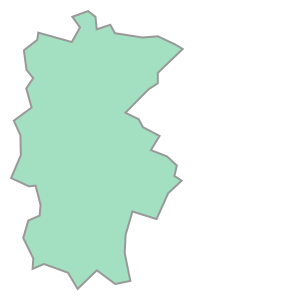

In [97]:
gpf_scpo.loc[281, 'geometry']

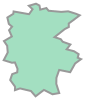

In [98]:
gpf_scpo_4326.loc[281, 'geometry']

Let's compare the geometry between the map from insee and the map from science po after conversion

In [ ]:
gpf.head(5)

,id_circo,dep,libelle,geometry
0,97302,973,Guyane - 2e circonscription,"MULTIPOLYGON (((-54.60236 2.33356, -54.60242 2..."
1,97301,973,Guyane - 1re circonscription,"MULTIPOLYGON (((-51.93691 4.46648, -51.93667 4..."
2,97201,972,Martinique - 1re circonscription,"MULTIPOLYGON (((-61.00495 14.57791, -61.00492 ..."
3,97202,972,Martinique - 2e circonscription,"MULTIPOLYGON (((-61.12889 14.63162, -61.1289 1..."
4,97203,972,Martinique - 3e circonscription,"POLYGON ((-61.03945 14.64265, -61.0394 14.6425..."


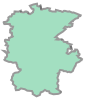

In [109]:
gpf_insee_6501 = gpf[gpf['id_circo'] == '6501']
gpf_insee_6501.geometry.loc[204]

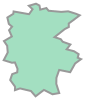

In [111]:
gpf_scpo_4326_6501 = gpf_scpo_4326[gpf_scpo_4326['code_circo'] == '6501']
gpf_scpo_4326_6501.geometry.loc[281] 

In [117]:
gpf_scpo_4326_6501.geometry.loc[281].wkt


'POLYGON ((0.2441359999612985 43.372719000717396, 0.29875899955169 43.3885800012338, 0.3254069996355788 43.37477700107291, 0.3313500002304112 43.342654001068134, 0.3785479999926962 43.355366000773635, 0.3958229999616947 43.33424400110557, 0.4935400001247597 43.325482001169945, 0.5470689999210768 43.32980600101836, 0.6068109997506554 43.31088600092053, 0.635725000138743 43.29913900096608, 0.5509570000989215 43.23600800107079, 0.5518750001658344 43.209147000731946, 0.5206550001889031 43.1932610010149, 0.4417050001720943 43.130969001068685, 0.4892900004469988 43.115179000855726, 0.5045900003649278 43.095359000955355, 0.5638540003436144 43.07424700112384, 0.5351199998805581 43.03705100091048, 0.5918249996520987 43.02237300081566, 0.6273959995891377 42.999733000867174, 0.6201210004472346 42.97243600073903, 0.6459590004192185 42.96133600071808, 0.600186999813668 42.928015000874346, 0.5623410002499056 42.860757000846405, 0.4773570002999967 42.87824400077313, 0.4561709996886626 42.817599000671

In [118]:
gpf_insee_6501.geometry.loc[204].wkt

'MULTIPOLYGON (((0.4830604063183891 42.705503707697346, 0.4830604064776044 42.705503707862654, 0.4817158601524806 42.71204818706472, 0.4817158601524846 42.71204818706472, 0.4830604064776088 42.705503707862654, 0.4830604063183891 42.705503707697346)), ((0.4615583259625171 42.746043728509754, 0.4621240558495078 42.73920210419068, 0.4621240558495014 42.73920210419068, 0.4621229533359911 42.73920148641539, 0.4512969153610559 42.7331341316649, 0.4512969153610507 42.7331341316649, 0.4512969161113893 42.73313413114504, 0.4512969153610574 42.73313413072446, 0.451296915361057 42.733134130724345, 0.4817158601524877 42.71204818612436, 0.4817158601524865 42.71204818612424, 0.4830604063183891 42.705503707697346, 0.4830600805483114 42.70550336954473, 0.4777498324171892 42.6999906398778, 0.4777498324171839 42.6999906398778, 0.4624964259625702 42.693737811203256, 0.462496425962575 42.69373781120317, 0.4257243057548753 42.69080794313774, 0.3959302250178021 42.69962321715297, 0.3926302822065261 42.71311

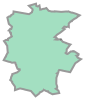

In [120]:
gpd.overlay(gpf_insee_6501, gpf_scpo_4326_6501, how='intersection').geometry.loc[0]

Conclusion : the map from the SciencePO service is not precise enough in case of dense cities with circonscription limit passing through.

#### Test the TOM to check if the the drawing of the circonscription limits is precise enough

###### Nouvelle calédonie

Nouméa city is the only part of the mainland in the 1st circo. We test a few geo point clos to the limit between the two circo (i.e. at the limit of Nouméa)
The Part of the "Coeur de Ville" is considered in the 1st circo, while it should be in the 2nd

In [52]:
from shapely.geometry import Point

#point = Point(test_address_geocode_coordinates[0], test_address_geocode_coordinates[1])
test_instant_coordinates = [-22.223520393592832, 166.46432883107758]

point = Point(test_instant_coordinates[1], test_instant_coordinates[0])

for i in range(len(gpf_scpo_4326)):
    polygon = gpf_scpo_4326.loc[i, 'geometry']
    if polygon.contains(point):
        print(f"The point is inside the polygon with index {i}. The circonscription is {gpf_scpo_4326.loc[i, 'Circonscription']} du département {gpf_scpo_4326.loc[i, 'nom_dpt']}.")
        break

The point is inside the polygon with index 558. The circonscription is 1ère circonscription du département NOUVELLE-CALEDONIE.


##### Polynésie Française

Papeete and Faaa are respectively in the 1st circo and in the  3rd circo.
Arue and Mahina are respectively in the 1st circo and in the 2nd circo.

Some addresses at the limits of the circo are considered in the neighbouring circo.

In [64]:
from shapely.geometry import Point

#point = Point(test_address_geocode_coordinates[0], test_address_geocode_coordinates[1])
test_instant_coordinates = [-17.514766903790864, -149.50246551792]

point = Point(test_instant_coordinates[1], test_instant_coordinates[0])

for i in range(len(gpf_scpo_4326)):
    polygon = gpf_scpo_4326.loc[i, 'geometry']
    if polygon.contains(point):
        print(f"The point is inside the polygon with index {i}. The circonscription is {gpf_scpo_4326.loc[i, 'Circonscription']} du département {gpf_scpo_4326.loc[i, 'nom_dpt']}.")
        break

The point is inside the polygon with index 564. The circonscription is 2ème circonscription du département POLYNESIE-FRANCAISE.


## Step 3 : How to deal with multiple results sent by the Geocodage API

In [14]:
#address to geocode
address_multi = "castets-en-dorthe, 33120, France"

response_multi = requests.get(
    server_name + "/search", #endpoint of the geocoding service
    params={
        "q": address_multi,
        "format": "json",
        "index": "address,poi", #index to search in, can be address or poi (point of interest or admin unit)
        "limit": "10" #max number of results to return
    }
)

test_address_multi_geocode = response_multi.json()

#print pretty json
print(json.dumps(test_address_multi_geocode, indent=4, ensure_ascii=False))


{
    "type": "FeatureCollection",
    "features": [
        {
            "type": "Feature",
            "geometry": {
                "type": "Point",
                "coordinates": [
                    -0.152642,
                    44.562103
                ]
            },
            "properties": {
                "label": "Rue du Ra 33210 Castets et Castillon",
                "score": 0.47026363636363633,
                "id": "33106_0070",
                "banId": "30008b96-d8cd-4f23-81e7-484e7491fc42",
                "name": "Rue du Ra",
                "postcode": "33210",
                "citycode": "33106",
                "oldcitycode": "33106",
                "x": 449698.36,
                "y": 6389777.99,
                "city": "Castets et Castillon",
                "oldcity": "Castets-en-Dorthe",
                "context": "33, Gironde, Nouvelle-Aquitaine",
                "type": "street",
                "importance": 0.4479,
                "depcode": "33",
 

In [15]:
# create dictionnary with labels and coordinates of the results
results_dict = {}

for i in range(len(test_address_multi_geocode["features"])):

    name = test_address_multi_geocode["features"][i]["properties"]["name"]
    if type(name) is list :
        name = name[0] #get the first name of the result
    coords = test_address_multi_geocode["features"][i]["geometry"]["coordinates"]
    
    results_dict[name] = coords

print("Results:", results_dict)


Results: {'Rue du Ra': [-0.152642, 44.562103], 'Route Jean Douence': [-0.151516, 44.556648], 'Rue Benoit': [-0.154102, 44.55775], 'Impasse du Brana': [-0.154131, 44.554844], 'Route du Grava': [-0.132538, 44.553882], 'Impasse la Grange': [-0.140395, 44.55592], 'Place du Casse': [-0.153743, 44.557156], 'Rue du Port': [-0.1556, 44.563142], 'Route de Langon': [-0.156773, 44.561326], 'Impasse Cantau': [-0.121436, 44.549544]}


In [16]:
# find the circonscription for each result
for label, coords in results_dict.items():
    point = Point(coords[0], coords[1])
    for i in range(len(gpf)):
        polygon = gpf.loc[i, 'geometry']
        if polygon.contains(point):
            print(f"The point '{label}' is inside the polygon with index {i}. The circonscription is {gpf.loc[i, 'libelle']} et son uid est {gpf.loc[i, 'id_circo']}.")
            break

The point 'Rue du Ra' is inside the polygon with index 141. The circonscription is Gironde - 9e circonscription et son uid est 3309.
The point 'Route Jean Douence' is inside the polygon with index 141. The circonscription is Gironde - 9e circonscription et son uid est 3309.
The point 'Rue Benoit' is inside the polygon with index 141. The circonscription is Gironde - 9e circonscription et son uid est 3309.
The point 'Impasse du Brana' is inside the polygon with index 141. The circonscription is Gironde - 9e circonscription et son uid est 3309.
The point 'Route du Grava' is inside the polygon with index 141. The circonscription is Gironde - 9e circonscription et son uid est 3309.
The point 'Impasse la Grange' is inside the polygon with index 141. The circonscription is Gironde - 9e circonscription et son uid est 3309.
The point 'Place du Casse' is inside the polygon with index 141. The circonscription is Gironde - 9e circonscription et son uid est 3309.
The point 'Rue du Port' is inside 

# 4. Generate GeoJson from INSEE map

## Download file from INSEE website

https://www.data.gouv.fr/datasets/portraits-des-circonscriptions-legislatives-indicateurs-economiques-et-socio-demographiques

In [35]:
import requests, zipfile, io

url = "https://www.data.gouv.fr/api/1/datasets/r/dbf42fce-a563-412e-9db1-1f7ab453c2ef"
r = requests.get(url)
#pass the rquest content to a zipfile object
z = zipfile.ZipFile(io.BytesIO(r.content))
#print the list of files in the zip
print("Files in the zip:", z.namelist())

Files in the zip: ['circonscriptions_legislatives_030522.cpg', 'circonscriptions_legislatives_030522.dbf', 'circonscriptions_legislatives_030522.prj', 'circonscriptions_legislatives_030522.shp', 'circonscriptions_legislatives_030522.shx']


## Convert Shape File from ZipFolder to GeoJson

/!\ need to install fiona module

### Below a method with Fiona (too long)

In [41]:
import geopandas as gpd
from fiona.io import ZipMemoryFile

#select the shapefile from the zip file

#pass the zip file to geopandas using ZipMemoryFile
with (ZipMemoryFile(r.content) as memfile):
    with memfile.open("circonscriptions_legislatives_030522.shp") as src:
        crs = src.crs
        gdf2 = gpd.GeoDataFrame.from_features(src, crs=crs)

gdf2.head()


,geometry,id_circo,dep,libelle
0,"MULTIPOLYGON (((-54.60236 2.33356, -54.60242 2...",97302,973,Guyane - 2e circonscription
1,"MULTIPOLYGON (((-51.93691 4.46648, -51.93667 4...",97301,973,Guyane - 1re circonscription
2,"MULTIPOLYGON (((-61.00495 14.57791, -61.00492 ...",97201,972,Martinique - 1re circonscription
3,"MULTIPOLYGON (((-61.12889 14.63162, -61.1289 1...",97202,972,Martinique - 2e circonscription
4,"POLYGON ((-61.03945 14.64265, -61.0394 14.6425...",97203,972,Martinique - 3e circonscription


### Below a method using the read_file geopandas method

In [42]:
gdf = gpd.read_file(r.content)
gdf.head()

,id_circo,dep,libelle,geometry
0,97302,973,Guyane - 2e circonscription,"MULTIPOLYGON (((-54.60236 2.33356, -54.60242 2..."
1,97301,973,Guyane - 1re circonscription,"MULTIPOLYGON (((-51.93691 4.46648, -51.93667 4..."
2,97201,972,Martinique - 1re circonscription,"MULTIPOLYGON (((-61.00495 14.57791, -61.00492 ..."
3,97202,972,Martinique - 2e circonscription,"MULTIPOLYGON (((-61.12889 14.63162, -61.1289 1..."
4,97203,972,Martinique - 3e circonscription,"POLYGON ((-61.03945 14.64265, -61.0394 14.6425..."


In [43]:
gdf.to_file("circo.geojson", driver="GeoJSON")

the geojson file size is about 24Mo.

We need to simplify the polygons to reduce the size if the file.

In [46]:
gdf["geometry"].head(10)

0    MULTIPOLYGON (((-54.60236 2.33356, -54.60242 2...
1    MULTIPOLYGON (((-51.93691 4.46648, -51.93667 4...
2    MULTIPOLYGON (((-61.00495 14.57791, -61.00492 ...
3    MULTIPOLYGON (((-61.12889 14.63162, -61.1289 1...
4    POLYGON ((-61.03945 14.64265, -61.0394 14.6425...
5    MULTIPOLYGON (((-60.86704 14.39146, -60.86694 ...
6    MULTIPOLYGON (((-61.2246 15.96451, -61.22459 1...
7    MULTIPOLYGON (((-61.10991 16.17325, -61.10971 ...
8    MULTIPOLYGON (((-61.56906 16.11092, -61.56923 ...
9    MULTIPOLYGON (((-61.61108 15.83956, -61.61092 ...
Name: geometry, dtype: geometry

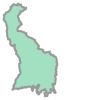

In [50]:
gdf["geometry"].iloc[4]

In [52]:
gdf.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 558 entries, 0 to 557
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   id_circo  558 non-null    str     
 1   dep       558 non-null    str     
 2   libelle   558 non-null    str     
 3   geometry  558 non-null    geometry
dtypes: geometry(1), str(3)
memory usage: 37.7 KB


# Downloading map directly from INSEE website
Source from datagouv have missing circos

the link to the map directly from the INSEE website : https://www.insee.fr/fr/statistiques/fichier/6441661/contours_circonscriptions_legislatives_03052022.zip

In [53]:
import requests, zipfile, io

url = "https://www.insee.fr/fr/statistiques/fichier/6441661/contours_circonscriptions_legislatives_03052022.zip"
r = requests.get(url)
#pass the rquest content to a zipfile object
z = zipfile.ZipFile(io.BytesIO(r.content))
#print the list of files in the zip
print("Files in the zip:", z.namelist())

Files in the zip: ['circonscriptions_legislatives_030522.cpg', 'circonscriptions_legislatives_030522.dbf', 'circonscriptions_legislatives_030522.prj', 'circonscriptions_legislatives_030522.shp', 'circonscriptions_legislatives_030522.shx']


In [55]:
import geopandas as gpd
gpf_insee = gpd.read_file(r.content)
gpf_insee.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 558 entries, 0 to 557
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   id_circo  558 non-null    str     
 1   dep       558 non-null    str     
 2   libelle   558 non-null    str     
 3   geometry  558 non-null    geometry
dtypes: geometry(1), str(3)
memory usage: 37.7 KB
